In [1]:
import pandas as pd

url = "https://huggingface.co/datasets/jason1966/algozee_employee-salary-prediction-dataset/resolve/main/job_salary_prediction_dataset.csv"

df = pd.read_csv(url)

print("Dataset shape:", df.shape)
display(df.head())

df.info()

Dataset shape: (250000, 10)


,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
0,AI Engineer,10,Bachelor,2,Healthcare,Medium,India,Hybrid,2,109413
1,Data Analyst,5,Bachelor,17,Telecom,Small,Australia,No,0,93764
2,Frontend Developer,18,PhD,4,Media,Medium,Singapore,No,1,148123
3,Business Analyst,19,PhD,13,Retail,Medium,Canada,Yes,0,189123
4,Product Manager,15,Bachelor,7,Manufacturing,Large,Sweden,Yes,0,165069


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 10 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   job_title         250000 non-null  object
 1   experience_years  250000 non-null  int64 
 2   education_level   250000 non-null  object
 3   skills_count      250000 non-null  int64 
 4   industry          250000 non-null  object
 5   company_size      250000 non-null  object
 6   location          250000 non-null  object
 7   remote_work       250000 non-null  object
 8   certifications    250000 non-null  int64 
 9   salary            250000 non-null  int64 
dtypes: int64(4), object(6)
memory usage: 19.1+ MB


In [2]:
# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Statistical summary
print("\nNumerical Feature Summary:")
display(df.describe())

# Categorical feature summary
print("\nCategorical Feature Summary:")
display(df.describe(include="object"))

Dataset Shape: (250000, 10)

Missing Values:
job_title           0
experience_years    0
education_level     0
skills_count        0
industry            0
company_size        0
location            0
remote_work         0
certifications      0
salary              0
dtype: int64

Duplicate Records: 0

Numerical Feature Summary:


,experience_years,skills_count,certifications,salary
count,250000.000000,250000.000000,250000.000000,250000.000000
mean,10.005408,9.997812,2.491928,145718.080524
std,6.060602,5.479288,1.706475,37407.952729
min,0.000000,1.000000,0.000000,31867.000000
25%,5.000000,5.000000,1.000000,119358.000000
50%,10.000000,10.000000,2.000000,143453.000000
75%,15.000000,15.000000,4.000000,169492.000000
max,20.000000,19.000000,5.000000,333046.000000



Categorical Feature Summary:


,job_title,education_level,industry,company_size,location,remote_work
count,250000,250000,250000,250000,250000,250000
unique,12,5,10,5,10,3
top,Backend Developer,Master,Finance,Large,Australia,No
freq,21125,50352,25393,50254,25258,83621


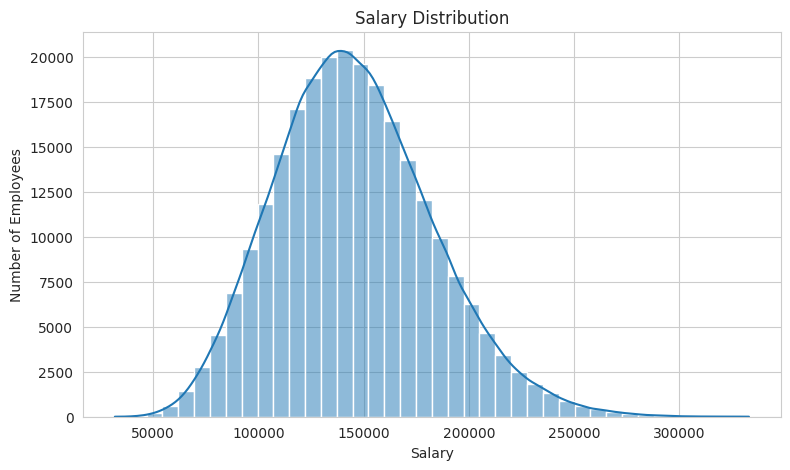

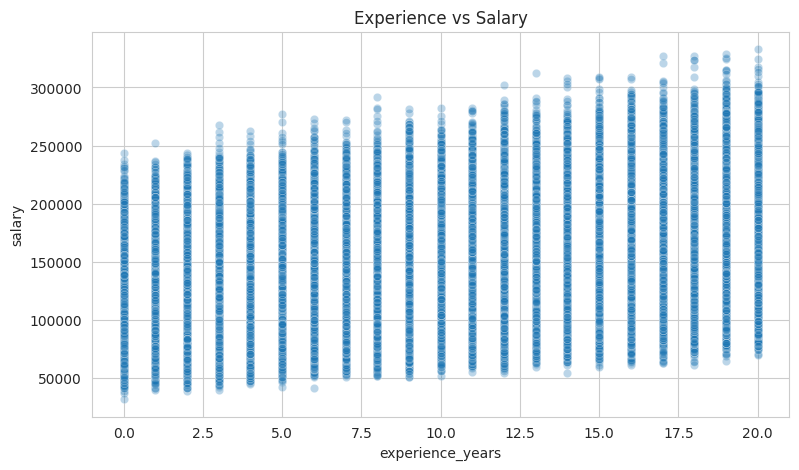

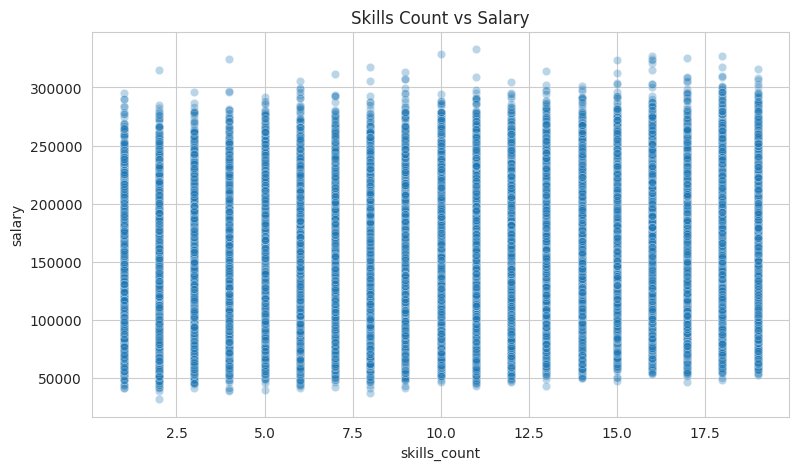

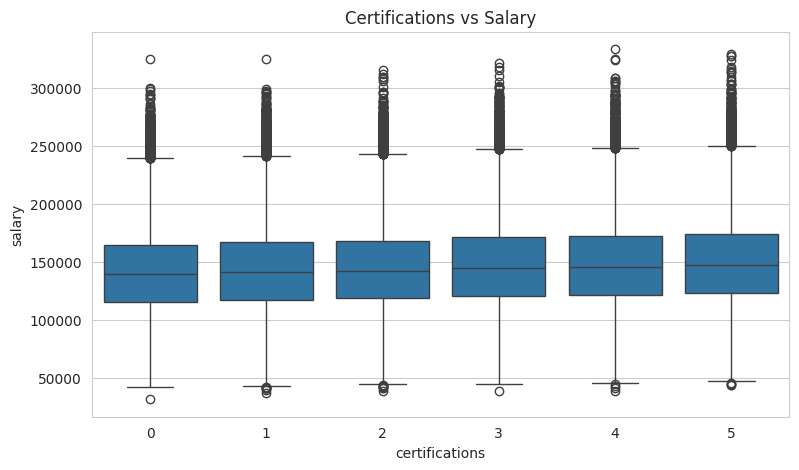

In [3]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# 1. Salary distribution
plt.figure(figsize=(9, 5))
sns.histplot(df['salary'], bins=40, kde=True)
plt.title("Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Number of Employees")
plt.show()

# 2. Experience vs Salary
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x='experience_years', y='salary',
                alpha=0.3)
plt.title("Experience vs Salary")
plt.show()

# 3. Skills Count vs Salary
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x='skills_count', y='salary',
                alpha=0.3)
plt.title("Skills Count vs Salary")
plt.show()

# 4. Certifications vs Salary
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='certifications', y='salary')
plt.title("Certifications vs Salary")
plt.show()


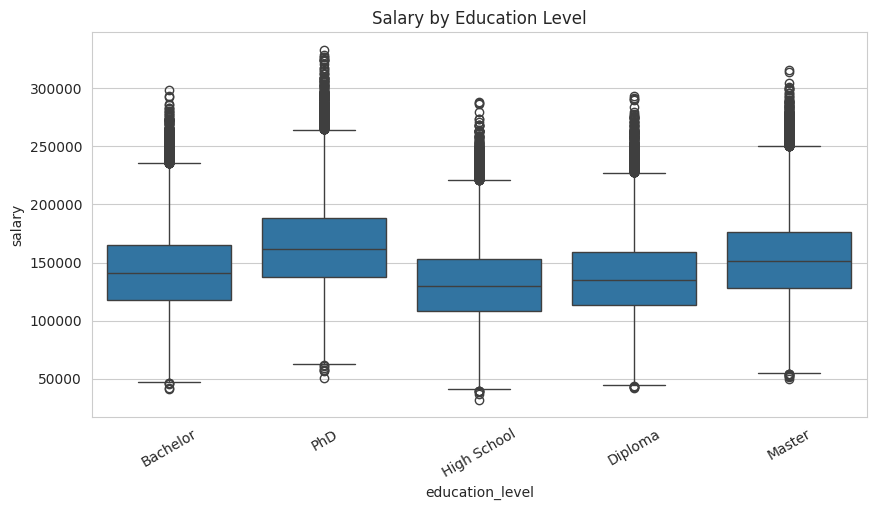

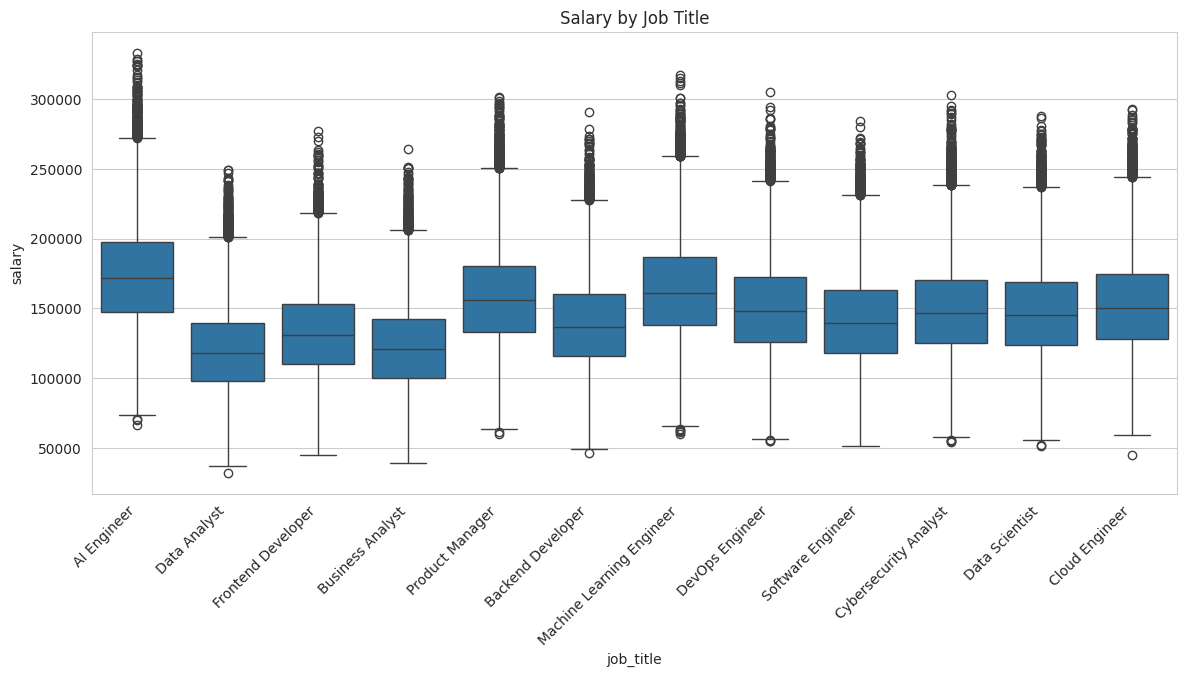

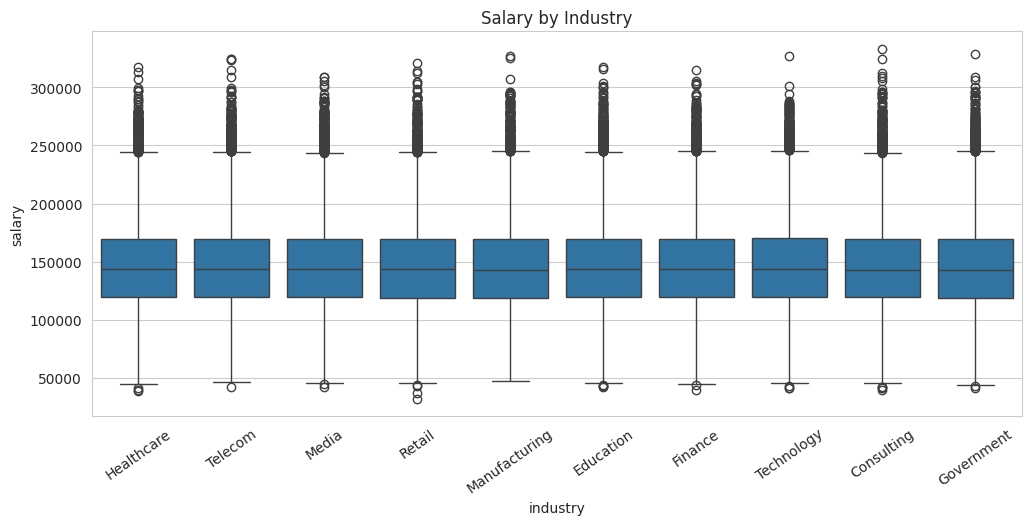

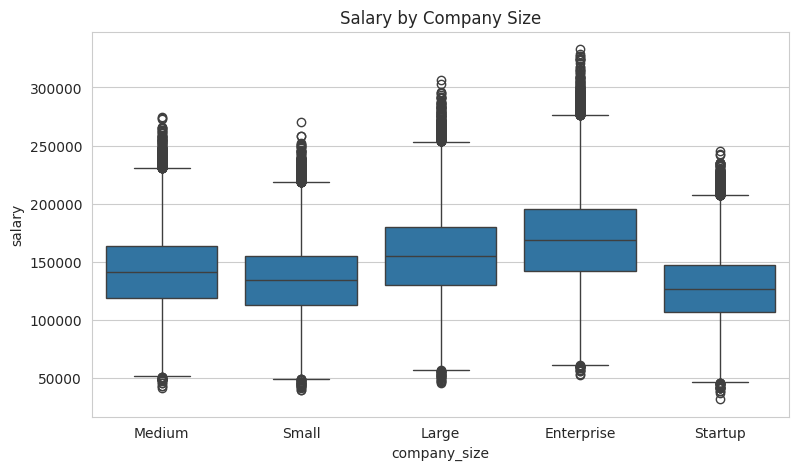

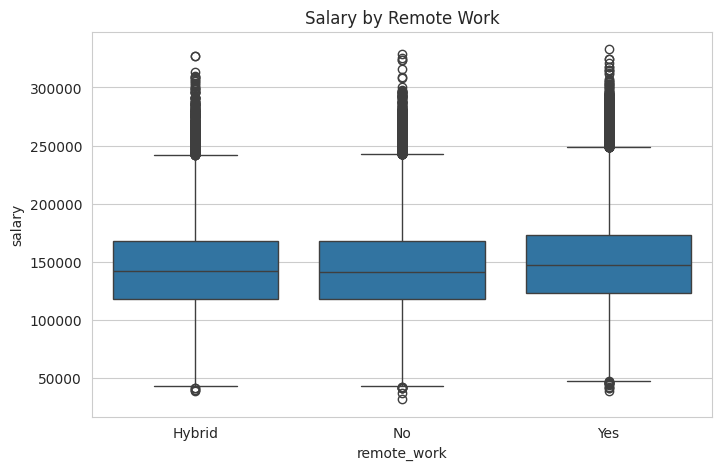

In [4]:

# Salary by Education Level
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='education_level', y='salary')
plt.title("Salary by Education Level")
plt.xticks(rotation=30)
plt.show()

# Salary by Job Title
plt.figure(figsize=(14, 6))
sns.boxplot(data=df, x='job_title', y='salary')
plt.title("Salary by Job Title")
plt.xticks(rotation=45, ha='right')
plt.show()

# Salary by Industry
plt.figure(figsize=(12, 5))
sns.boxplot(data=df, x='industry', y='salary')
plt.title("Salary by Industry")
plt.xticks(rotation=35)
plt.show()

# Salary by Company Size
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='company_size', y='salary')
plt.title("Salary by Company Size")
plt.show()

# Salary by Remote Work
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='remote_work', y='salary')
plt.title("Salary by Remote Work")
plt.show()


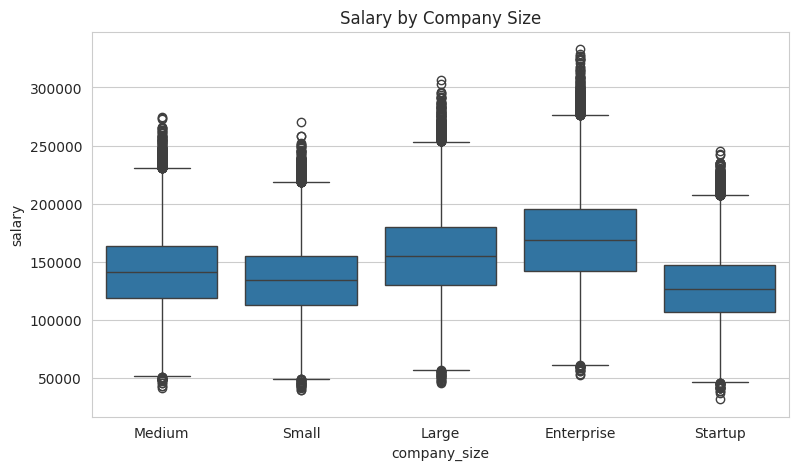

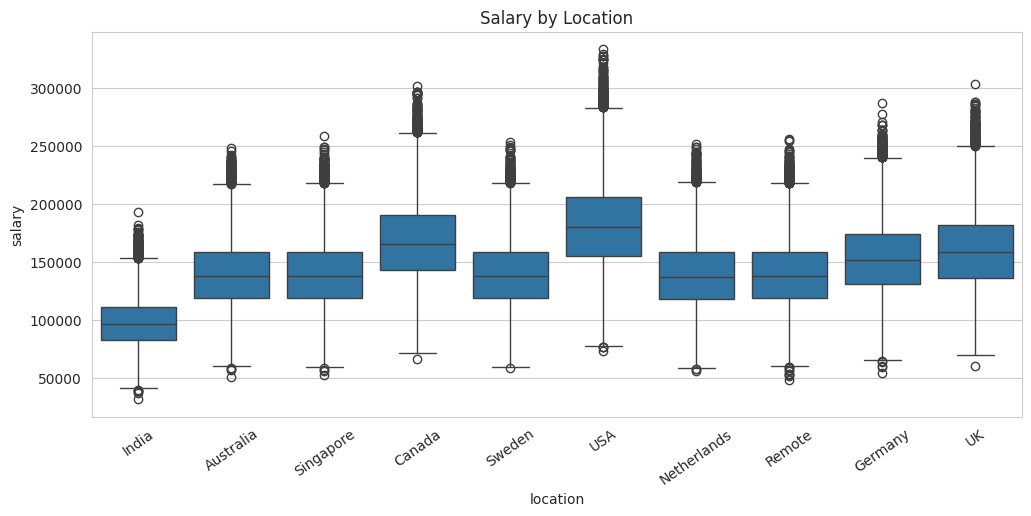

In [5]:

# Salary by Company Size
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='company_size', y='salary')
plt.title("Salary by Company Size")
plt.show()

# Salary by Location
plt.figure(figsize=(12, 5))
sns.boxplot(data=df, x='location', y='salary')
plt.title("Salary by Location")
plt.xticks(rotation=35)
plt.show()


In [6]:

# Average salary by category

categorical_columns = [
    'job_title',
    'education_level',
    'industry',
    'company_size',
    'location',
    'remote_work'
]

for column in categorical_columns:
    print(f"\nAverage Salary by {column}:")
    display(
        df.groupby(column)['salary']
        .agg(['mean', 'median', 'count'])
        .sort_values('mean', ascending=False)
        .round(2)
    )



Average Salary by job_title:


,mean,median,count
job_title,,,
AI Engineer,173498.48,171674.0,20945
Machine Learning Engineer,163022.50,160933.0,20677
Product Manager,157594.93,155655.5,20950
Cloud Engineer,152102.54,150005.0,20686
DevOps Engineer,149959.27,148021.0,20889
Cybersecurity Analyst,148697.70,146737.0,20959
Data Scientist,147258.21,145231.5,20890
Software Engineer,141739.52,139432.5,20876
Backend Developer,139202.77,136678.0,21125



Average Salary by education_level:


,mean,median,count
education_level,,,
PhD,163976.01,162005.0,49857
Master,153305.31,151396.5,50352
Bachelor,142410.53,140631.5,49950
Diploma,137158.57,135283.0,49776
High School,131715.34,129663.0,50065



Average Salary by industry:


,mean,median,count
industry,,,
Education,145993.56,143627.0,24889
Media,145891.27,143591.5,25034
Telecom,145876.51,143380.0,24859
Technology,145863.81,143359.0,24903
Finance,145801.64,143858.0,25393
Healthcare,145760.00,143998.5,24898
Government,145613.87,143176.0,24901
Manufacturing,145530.60,143119.5,25024
Consulting,145451.64,143202.0,25258


... (2 outputs left out)


Average Salary by location:


,mean,median,count
location,,,
USA,181716.30,179647.0,24931
Canada,167391.27,165474.0,25165
UK,160075.14,158191.0,24927
Germany,153376.21,151538.0,24763
Remote,139442.53,137836.0,25065
Sweden,139440.64,138033.0,25100
Australia,139362.15,137753.5,25258
Singapore,139340.70,137699.0,25035
Netherlands,139294.81,137356.0,24861



Average Salary by remote_work:


,mean,median,count
remote_work,,,
Yes,149279.59,147153.0,82903
Hybrid,143969.90,141672.0,83476
No,143932.30,141630.0,83621


**Prepare data for machine learning**

In [7]:

# Separate input features and target variable

X = df.drop('salary', axis=1)
y = df['salary']

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget variable:")
print(y.name)


Feature dataset shape: (250000, 9)
Target dataset shape: (250000,)

Input features:
['job_title', 'experience_years', 'education_level', 'skills_count', 'industry', 'company_size', 'location', 'remote_work', 'certifications']

Target variable:
salary


In [8]:

# Identify numerical and categorical columns

numerical_features = [
    'experience_years',
    'skills_count',
    'certifications'
]

categorical_features = [
    'job_title',
    'education_level',
    'industry',
    'company_size',
    'location',
    'remote_work'
]

print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)


Numerical features: ['experience_years', 'skills_count', 'certifications']

Categorical features: ['job_title', 'education_level', 'industry', 'company_size', 'location', 'remote_work']


In [9]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (200000, 9)
Testing features: (50000, 9)
Training target: (200000,)
Testing target: (50000,)


In [10]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Preprocess numerical and categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


**Train our first model: Single Linear Regression**

In [11]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Select only experience as the input feature
X_train_single = X_train[['experience_years']]
X_test_single = X_test[['experience_years']]

# Train the model
single_model = LinearRegression()
single_model.fit(X_train_single, y_train)

# Make predictions
y_pred_single = single_model.predict(X_test_single)

# Evaluate the model
rmse_single = np.sqrt(mean_squared_error(y_test, y_pred_single))
mae_single = mean_absolute_error(y_test, y_pred_single)
r2_single = r2_score(y_test, y_pred_single)

print("Single Linear Regression Results")
print("--------------------------------")
print("RMSE:", round(rmse_single, 2))
print("MAE:", round(mae_single, 2))
print("R2 Score:", round(r2_single, 4))


Single Linear Regression Results
--------------------------------
RMSE: 33584.33
MAE: 26585.24
R2 Score: 0.1885


**Multiple Linear Regression**

In [12]:

from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Create the complete Multiple Linear Regression pipeline
multiple_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

# Train the model
multiple_model.fit(X_train, y_train)

# Predict salaries
y_pred_multiple = multiple_model.predict(X_test)

# Evaluate the model
rmse_multiple = np.sqrt(
    mean_squared_error(y_test, y_pred_multiple)
)

mae_multiple = mean_absolute_error(
    y_test, y_pred_multiple
)

r2_multiple = r2_score(
    y_test, y_pred_multiple
)

print("Multiple Linear Regression Results")
print("----------------------------------")
print("RMSE:", round(rmse_multiple, 2))
print("MAE:", round(mae_multiple, 2))
print("R2 Score:", round(r2_multiple, 4))


Multiple Linear Regression Results
----------------------------------
RMSE: 7125.52
MAE: 5436.1
R2 Score: 0.9635


In [13]:

comparison = pd.DataFrame({
    'Model': [
        'Single Linear Regression',
        'Multiple Linear Regression'
    ],
    'RMSE': [
        rmse_single,
        rmse_multiple
    ],
    'MAE': [
        mae_single,
        mae_multiple
    ],
    'R2 Score': [
        r2_single,
        r2_multiple
    ]
})

display(comparison.round(4))


,Model,RMSE,MAE,R2 Score
0,Single Linear Regression,33584.3315,26585.2412,0.1885
1,Multiple Linear Regression,7125.5217,5436.0973,0.9635


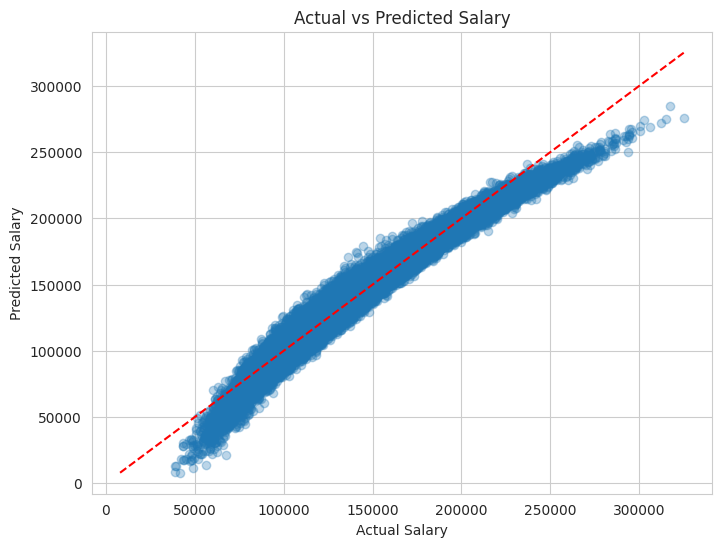

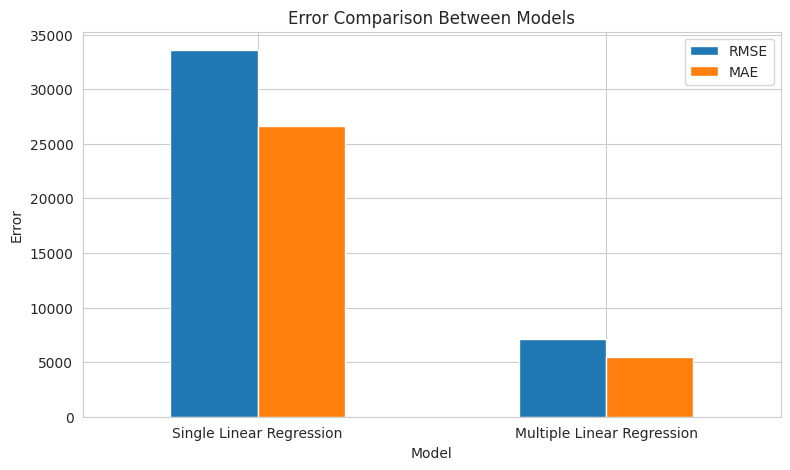

In [14]:

# Compare actual and predicted salaries
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_multiple, alpha=0.3)

plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Actual vs Predicted Salary")

# Perfect prediction reference line
minimum = min(y_test.min(), y_pred_multiple.min())
maximum = max(y_test.max(), y_pred_multiple.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    'r--'
)

plt.show()


# Compare model evaluation metrics
comparison.set_index('Model')[['RMSE', 'MAE']].plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title("Error Comparison Between Models")
plt.ylabel("Error")
plt.xticks(rotation=0)
plt.show()


In [15]:
# Correlation between numerical features and salary
correlation = df[
    ['experience_years', 'skills_count',
     'certifications', 'salary']
].corr()

display(correlation.round(3))

,experience_years,skills_count,certifications,salary
experience_years,1.000,0.000,-0.000,0.438
skills_count,0.000,1.000,-0.002,0.127
certifications,-0.000,-0.002,1.000,0.074
salary,0.438,0.127,0.074,1.000


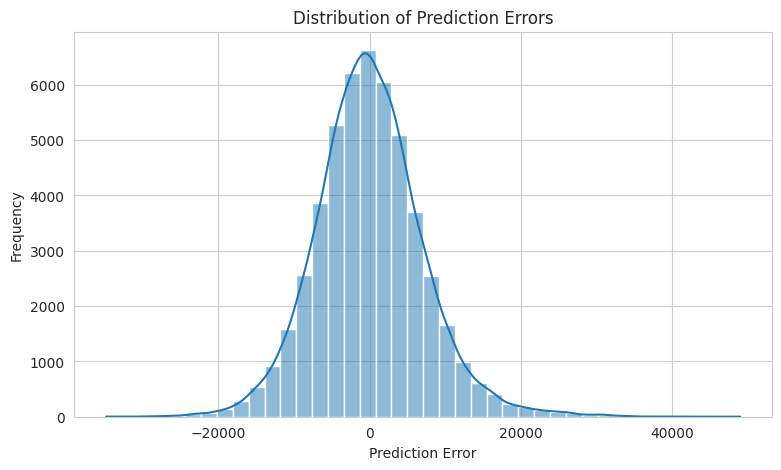

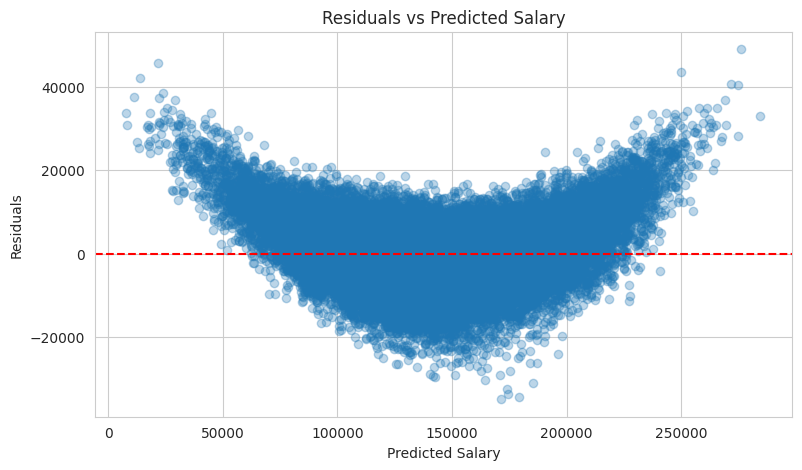

Mean Residual: 10.18
Standard Deviation: 7125.59


In [16]:

# Calculate prediction errors
residuals = y_test - y_pred_multiple

# Residual distribution
plt.figure(figsize=(9, 5))
sns.histplot(residuals, bins=40, kde=True)

plt.title("Distribution of Prediction Errors")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.show()

# Residuals against predicted salary
plt.figure(figsize=(9, 5))
plt.scatter(y_pred_multiple, residuals, alpha=0.3)

plt.axhline(y=0, color='red', linestyle='--')

plt.title("Residuals vs Predicted Salary")
plt.xlabel("Predicted Salary")
plt.ylabel("Residuals")
plt.show()

print("Mean Residual:", round(residuals.mean(), 2))
print("Standard Deviation:", round(residuals.std(), 2))


In [17]:

from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    multiple_model,
    X_train,
    y_train,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

print("5-Fold Cross-Validation R2 Scores:")
print(cv_scores)

print("\nMean CV R2:", round(cv_scores.mean(), 4))
print("Standard Deviation:", round(cv_scores.std(), 4))


5-Fold Cross-Validation R2 Scores:
[0.96305837 0.96343261 0.96364969 0.96319319 0.96336065]

Mean CV R2: 0.9633
Standard Deviation: 0.0002


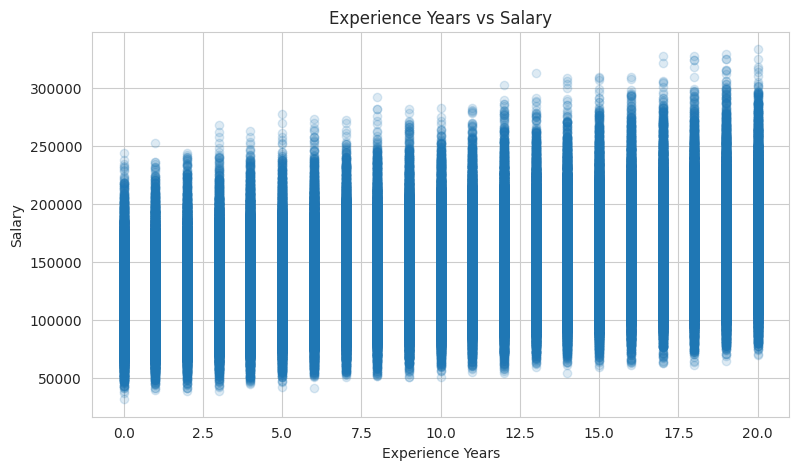

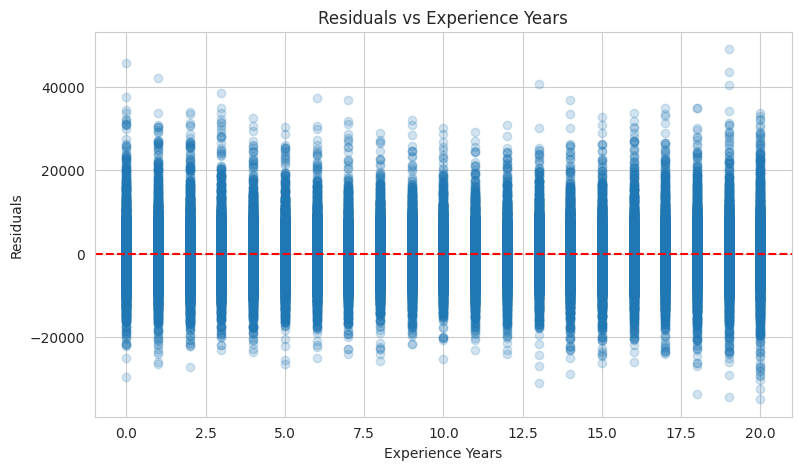

In [18]:

# Examine experience against salary

plt.figure(figsize=(9, 5))

plt.scatter(
    df['experience_years'],
    df['salary'],
    alpha=0.15
)

plt.title("Experience Years vs Salary")
plt.xlabel("Experience Years")
plt.ylabel("Salary")
plt.show()


# Examine residuals against experience

plt.figure(figsize=(9, 5))

plt.scatter(
    X_test['experience_years'],
    residuals,
    alpha=0.2
)

plt.axhline(0, color='red', linestyle='--')

plt.title("Residuals vs Experience Years")
plt.xlabel("Experience Years")
plt.ylabel("Residuals")
plt.show()


In [19]:

from sklearn.preprocessing import PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Apply polynomial features to numerical columns
polynomial_preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('poly', PolynomialFeatures(
                degree=2,
                include_bias=False
            ))
        ]), numerical_features),

        ('cat', OneHotEncoder(
            handle_unknown='ignore'
        ), categorical_features)
    ]
)

# Create polynomial regression model
polynomial_model = Pipeline([
    ('preprocessor', polynomial_preprocessor),
    ('regressor', LinearRegression())
])

# Train model
polynomial_model.fit(X_train, y_train)

# Predictions
y_pred_poly = polynomial_model.predict(X_test)

# Evaluation
rmse_poly = np.sqrt(
    mean_squared_error(y_test, y_pred_poly)
)

mae_poly = mean_absolute_error(
    y_test, y_pred_poly
)

r2_poly = r2_score(y_test, y_pred_poly)

print("Polynomial Regression Results")
print("--------------------------------")
print("RMSE:", round(rmse_poly, 2))
print("MAE:", round(mae_poly, 2))
print("R2 Score:", round(r2_poly, 4))


Polynomial Regression Results
--------------------------------
RMSE: 7125.58
MAE: 5436.2
R2 Score: 0.9635


In [20]:

import joblib

# Save the best model
joblib.dump(
    multiple_model,
    'final_salary_prediction_model.pkl'
)

print("Final Salary Prediction Model saved successfully!")


Final Salary Prediction Model saved successfully!


In [21]:
from google.colab import files

files.download('final_salary_prediction_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>